# Notebook of exploration possible overintegration (old cell type labels)

Here we explore the concept of over-integration of healthy samples (not current anymore as we will only assess disease of overintegration)

In [1]:
# import os
# os.chdir('../')
import warnings

warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

In [216]:
import scanpy as sc
import anndata
import matplotlib.pyplot as plt
import numpy as np
import scipy
import pandas as pd
import json
import seaborn as sb

In [3]:
workspace = "C:\\Users\\49176\\PycharmProjects\\Bachelor\\HLCA\\MapAnalyzer_Results_2.0"

In [21]:
ad_storage = "C:\\Users\\49176\\PycharmProjects\\Bachelor\\HLCA\\Adatas\\local.h5ad"

In [121]:
def set_clean_labels(obs):

    label_file = open(f"{workspace}\\label_mapping.txt")
    labels_dict = json.load(label_file)
    
    new_dict={}
    for k, v in labels_dict.items():
        if "_" in k:
            k = k.split("_")[1]
        if "_" in v:
            v = v.split("_")[1]
        new_dict[k]=v
    
    labels_dict=new_dict
    
    level_file = open(f"{workspace}\\label_mapping_levels.txt")
    levels_dict = json.load(level_file)

    obs["cell_label"] = obs.ann_finest_level

    obs["cell_label"] = obs.ann_finest_level.replace(labels_dict)

    obs["cell_label"] = obs["cell_label"].astype(str)

    obs["cell_label"] = obs["cell_label"].astype("category")
    # clean up labels from number prefixes
    clean_labels = {}
    for ct in obs.cell_label.cat.categories:
        if "_" in ct:
            ct_new = ct.split("_")[1]
        else:
            ct_new = ct
        clean_labels[ct] = ct_new

    obs["cell_label"] = obs["cell_label"].replace(clean_labels)
    level_file.close()
    label_file.close()
    return obs

#### Add scores to adata

In [94]:
scores = pd.read_csv(f'{workspace}\\baseline_excluded.csv')
scores.index = scores["Unnamed: 0"]

In [112]:
adata= sc.read_h5ad(ad_storage,backed="r")

In [280]:
obs = adata.obs

In [281]:
obs= pd.merge(obs,scores,left_index=True,right_index=True)

In [282]:
obs = set_clean_labels(obs)

In [283]:
obs.cell_label

GCGACCATCCCTAACC_SC22      Macrophages
P2_1_GCGCAACCAGTTAACC         NK cells
GCTCTGTAGTGCTGCC_SC27              AT2
P2_8_TTAGGACGTTCAGGCC      Macrophages
CTTGATTGTCAGTTTG_T164            Basal
                              ...     
ACCTTTACATTAACCG_T120            Basal
CATTATCTCCATGAAC_F01639            DC2
AGGCCGTGTGTGACCC-SC56              AT2
CGATGGCAGCAGGCTA-1-2         Secretory
AATCGGTGTCGGCACT-1-4         Secretory
Name: cell_label, Length: 584944, dtype: category
Categories (34, object): ['AT1', 'AT2', 'AT2 proliferating', 'B cells', ..., 'Secretory', 'Smooth muscle', 'Submucosal Secretory', 'T cells proliferating']

Group by cell label and sample and obtain sample size and log(sample size) for transformation

In [284]:
group = obs.groupby(["cell_label","sample"]).agg({"score":"mean","dataset":"count"})

In [285]:
group = group.reset_index(drop=False)

In [286]:
group=group.dropna()

In [287]:
group["dataset"] = np.log(group.dataset.to_numpy())

In [288]:
group["dataset"]

166     5.913503
167     5.852202
168     6.313548
169     5.135798
171     3.931826
          ...   
5141    5.129899
5142    5.843544
5143    5.926926
5144    4.941642
5145    6.107023
Name: dataset, Length: 1230, dtype: float64

In [289]:
transform = pd.read_csv(f"{workspace}\\transformation.csv")

Get the highest 5% of scores per cell type

In [290]:
perc_95={}

In [291]:
for ct in transform.cell_label:
    slope = transform.loc[transform.cell_label==ct,"slope"].to_numpy()
    intercept = transform.loc[transform.cell_label==ct,"intercept"].to_numpy()
    group.loc[group.cell_label == ct,"score"] = group.loc[group.cell_label == ct,"score"] - (group.loc[group.cell_label == ct,"dataset"]*slope+intercept)
    perc_95[ct]=np.percentile(group.loc[group.cell_label == ct,"score"].to_numpy(),95)

In [292]:
group.cell_label.cat.remove_unused_categories(inplace=True)

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14]),
 [Text(0, 0, 'AT2'),
  Text(1, 0, 'Basal'),
  Text(2, 0, 'CD4 T cells'),
  Text(3, 0, 'CD8 T cells'),
  Text(4, 0, 'Classical monocytes'),
  Text(5, 0, 'DC2'),
  Text(6, 0, 'EC arterial'),
  Text(7, 0, 'EC venous'),
  Text(8, 0, 'Fibroblast lineage'),
  Text(9, 0, 'Macrophages'),
  Text(10, 0, 'Mast cells'),
  Text(11, 0, 'Multiciliated'),
  Text(12, 0, 'NK cells'),
  Text(13, 0, 'Non-classical monocytes'),
  Text(14, 0, 'Secretory')])

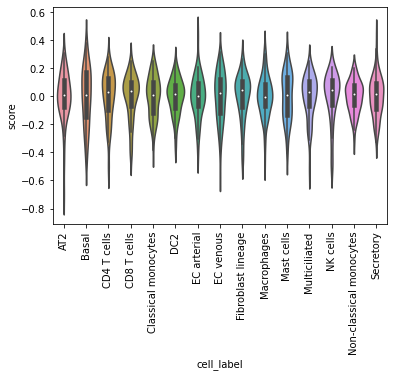

In [293]:
sb.violinplot(data=group,x="cell_label",y="score")
plt.xticks(rotation=90)

In [294]:
perc_95

{'AT2': 0.24208559327428325,
 'EC arterial': 0.2042389280308947,
 'Mast cells': 0.21997711914378568,
 'CD4 T cells': 0.19624120128378547,
 'CD8 T cells': 0.19425880388625055,
 'Classical monocytes': 0.2140970790967955,
 'NK cells': 0.18345104542015628,
 'Non-classical monocytes': 0.1762903034252462,
 'Basal': 0.3057626686975042,
 'DC2': 0.17603733103841335,
 'EC venous': 0.24450571536198804,
 'Fibroblast lineage': 0.20824000168787143,
 'Macrophages': 0.24344592345973293,
 'Multiciliated': 0.190028198859002,
 'Secretory': 0.20171335560258127}

Iterate over samples and cell types where score is in top 5%: possibly overintegrated? BUT: all healthy

In [305]:
datasets=["Meyer_2021","Schiller_2020","Schultze_unpubl","Sims_2019","Gomperts_2021","Schiller_2021"]

In [307]:
for dataset in datasets:
    rep=pd.read_csv(f"{workspace}\\{dataset}\\report.csv")
    print(dataset)
    for k,v in perc_95.items():
        d=rep[(rep.cell_label==k) & (rep["mean"]>v)][["sample","health_status"]]
        if len(d)>0:
            print(d)

Meyer_2021
                sample health_status
79     5841STDY7991486       healthy
124  HCATisStab7732264       healthy
178        WSSS8015047       healthy
322        WSSS8123927       healthy
451    WTDAtest7732265       healthy
469    WTDAtest7732267       healthy
480    WTDAtest7732268       healthy
486    WTDAtest7732269       healthy
495    WTDAtest7732270       healthy
               sample health_status
97  HCATisStab7732261       healthy
                sample health_status
133        WSSS8015042       healthy
148        WSSS8015044       healthy
158        WSSS8015045       healthy
168        WSSS8015046       healthy
177        WSSS8015047       healthy
250        WSSS8062680       healthy
409  WSSS_A_LNG8620063       healthy
433  WSSS_A_LNG8620066       healthy
                sample health_status
102  HCATisStab7732261       healthy
111  HCATisStab7732262       healthy
                sample health_status
137        WSSS8015042       healthy
154        WSSS8015044       